# **Laboratorio dirigido 12 — Analítica de procesos internos**

**Estudiante: Trilce Aranda Cuevas**

**Caso:** monitoreo de la temperatura de una máquina industrial y priorización de alertas operativas.
**Datos reales:** Numenta Anomaly Benchmark (NAB), serie `machine_temperature_system_failure`: lecturas cada 5 minutos del sensor de temperatura de un componente interno de una máquina industrial grande, del 2 de diciembre de 2013 al 19 de febrero de 2014. La fuente no indica la unidad de medida.
**Pregunta:** ¿qué lecturas y qué días merecen revisión primero, sin acusar una falla a partir de una simple rareza estadística?

> Referencia: Lavin, A. y Ahmad, S. (2015). *Evaluating Real-Time Anomaly Detection Algorithms — The Numenta Anomaly Benchmark.* 14th IEEE International Conference on Machine Learning and Applications.

## Objetivos y teoría
La detección de anomalías identifica observaciones poco habituales según un conjunto de variables. Isolation Forest produce una puntuación de rareza; el umbral se calibra exclusivamente con la línea base. La carta p monitorea la proporción diaria de lecturas en alerta con límites que dependen del número de lecturas de cada día. Una alerta es un motivo para investigar, no una prueba de falla.

Los autores de NAB señalan **ventanas de anomalía** en la serie. Se usan solo como referencia para contrastar las alertas **después** de calibrar el modelo: son ventanas aproximadas y la fuente no explica la causa de cada una.

## Paso 1. Cargar datos abiertos y conservar trazabilidad
Fuente de los datos: https://github.com/numenta/NAB/blob/master/data/realKnownCause/machine_temperature_system_failure.csv . Etiquetas: https://github.com/numenta/NAB/blob/master/labels/combined_windows.json . Licencia del repositorio: MIT (Numenta, 2014-2024).

In [ ]:
!pip -q install scikit-learn
import json
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
BASE_URL = "https://raw.githubusercontent.com/numenta/NAB/master/"
URL_DATOS = BASE_URL + "data/realKnownCause/machine_temperature_system_failure.csv"
URL_ETIQ = BASE_URL + "labels/combined_windows.json"
raw = pd.read_csv(URL_DATOS, parse_dates=["timestamp"])
print("Filas originales:", len(raw), "Columnas:", list(raw.columns))
print("Desde", raw.timestamp.min(), "hasta", raw.timestamp.max())
print(raw.head())

Filas originales: 22695 Columnas: ['timestamp', 'value']
Desde 2013-12-02 21:15:00 hasta 2014-02-19 15:25:00
            timestamp      value
0 2013-12-02 21:15:00  73.967322
1 2013-12-02 21:20:00  74.935882
2 2013-12-02 21:25:00  76.124162
3 2013-12-02 21:30:00  78.140707
4 2013-12-02 21:35:00  79.329836


## Paso 2. Reglas de calidad y variables derivadas
Se retiran las marcas de tiempo repetidas (se conserva la primera), se ordena la serie y se trabaja con días completos: del 3 de diciembre de 2013 al 18 de febrero de 2014. Son reglas analíticas declaradas, no verdades de la fuente. Las variables derivadas resumen la última hora (12 lecturas): media, desviación y cambio respecto de hace una hora.

In [ ]:
# Marcas de tiempo repetidas: se conserva la primera lectura de cada instante
repetidas = raw.timestamp.duplicated(keep="first")
df = raw.loc[~repetidas].sort_values("timestamp").set_index("timestamp")
# Se comprueba que todas las lecturas están separadas por 5 minutos
fuera_de_paso = int((df.index.to_series().diff().dropna() != pd.Timedelta(minutes=5)).sum())
# Solo días completos: el primer y el último día de la fuente están incompletos
df = df.loc["2013-12-03":"2014-02-18 23:59"].copy()
print("Marcas repetidas:", int(repetidas.sum()), "· lecturas útiles:", len(raw) - int(repetidas.sum()))
print("Lecturas fuera del paso de 5 min:", fuera_de_paso, "· lecturas en días completos:", len(df))
print(df.value.describe().round(2))
print("Lecturas por debajo de 20:", int((df.value < 20).sum()))
# Variables derivadas de la última hora; las 11 primeras lecturas no tienen historia suficiente
feat = pd.DataFrame({"valor": df.value,
                     "media_1h": df.value.rolling(12).mean(),
                     "desv_1h": df.value.rolling(12).std(),
                     "cambio_1h": df.value.diff(12)}).dropna()
print("Lecturas con variables completas:", len(feat))

Marcas repetidas: 12 · lecturas útiles: 22683
Lecturas fuera del paso de 5 min: 0 · lecturas en días completos: 22464
count    22464.00
mean        85.87
std         13.80
min          2.08
25%         83.03
50%         89.33
75%         94.00
max        108.51
Name: value, dtype: float64
Lecturas por debajo de 20: 12
Lecturas con variables completas: 22452


## Paso 3. Separar línea base y periodo de seguimiento
Línea base: 3 al 31 de diciembre de 2013. Seguimiento: 1 de enero al 18 de febrero de 2014. La separación se fija antes de examinar las alertas. Las ventanas de NAB se cargan solo para contrastar los resultados.

In [ ]:
CORTE = pd.Timestamp("2014-01-01")
base = feat.index < CORTE
# Ventanas de anomalía señaladas por los autores de NAB (solo referencia para contrastar)
etiquetas = json.load(urllib.request.urlopen(URL_ETIQ))["realKnownCause/machine_temperature_system_failure.csv"]
ventanas = [(pd.Timestamp(a), pd.Timestamp(b)) for a, b in etiquetas]
en_ventana = pd.Series(False, index=feat.index)
for a, b in ventanas:
    en_ventana.loc[a:b] = True
print("Línea base:", int(base.sum()), "lecturas · Seguimiento:", int((~base).sum()), "lecturas")
print("Ventanas de referencia:", [(str(a)[:16], str(b)[:16]) for a, b in ventanas])
assert base.sum() > 5000 and (~base).sum() > 10000

Línea base: 8340 lecturas · Seguimiento: 14112 lecturas
Ventanas de referencia: [('2013-12-10 06:25', '2013-12-12 05:35'), ('2013-12-15 17:50', '2013-12-17 17:00'), ('2014-01-27 14:20', '2014-01-29 13:30'), ('2014-02-07 14:55', '2014-02-09 14:05')]


## Paso 4. Detectar lecturas inusuales
El bosque se ajusta solo con la línea base. Una puntuación mayor significa una lectura más atípica. El percentil 99 de la puntuación base fija la alerta principal. El modelo aprende patrones estadísticos; no conoce la causa física de una lectura.

In [ ]:
modelo = IsolationForest(n_estimators=150, max_samples=5000, random_state=2026, n_jobs=-1)
# El modelo aprende lo normal solo con la línea base
modelo.fit(feat.loc[base])
# Puntuación de rareza: mayor valor significa lectura más atípica
feat["score"] = -modelo.score_samples(feat[["valor", "media_1h", "desv_1h", "cambio_1h"]])
# Umbral: percentil 99 de las puntuaciones de la línea base
umbral = feat.loc[base, "score"].quantile(0.99)
feat["alerta"] = feat.score >= umbral
print("Umbral:", round(umbral, 4))
print("Alertas en la línea base:", int(feat.loc[base, "alerta"].sum()))
print("Alertas en el seguimiento:", int(feat.loc[~base, "alerta"].sum()))

Umbral: 0.606
Alertas en la línea base: 84
Alertas en el seguimiento: 495


## Paso 5. Carta p con límites diarios
La proporción base p̄ es el total de alertas base dividido por el total de lecturas base. Cada límite superior usa el número n de lecturas del día. Se muestran todos los días, pero la evaluación de señales fuera de control se hace sobre el seguimiento. Las lecturas contiguas están correlacionadas, de modo que el supuesto binomial es una aproximación.

In [ ]:
diario = feat.groupby(feat.index.normalize()).agg(lecturas=("alerta", "size"), alertas=("alerta", "sum"))
pbar = feat.loc[base, "alerta"].mean()
diario["tasa"] = diario.alertas / diario.lecturas
diario["lsc"] = pbar + 3 * np.sqrt(pbar * (1 - pbar) / diario.lecturas)
diario["lic"] = np.maximum(0, pbar - 3 * np.sqrt(pbar * (1 - pbar) / diario.lecturas))
diario["fuera"] = (diario.tasa > diario.lsc) | (diario.tasa < diario.lic)
seguimiento = diario.loc[CORTE:].copy()
print("p̄ =", round(pbar, 5))
print(seguimiento[["lecturas", "alertas", "tasa", "lsc", "fuera"]].query("alertas > 0").to_string())
print("Días fuera de control en el seguimiento:", [str(d)[:10] for d in seguimiento.index[seguimiento.fuera]])
print("Días de la línea base fuera de límites:", int(diario.loc[:CORTE - pd.Timedelta(days=1), "fuera"].sum()), "de", int((diario.index < CORTE).sum()))

p̄ = 0.01007
            lecturas  alertas      tasa       lsc  fuera
timestamp                                               
2014-01-02       288        5  0.017361  0.027724  False
2014-01-05       288        8  0.027778  0.027724   True
2014-01-12       288       13  0.045139  0.027724   True
2014-01-16       288        8  0.027778  0.027724   True
2014-01-24       288       12  0.041667  0.027724   True
2014-01-31       288        1  0.003472  0.027724  False
2014-02-03       288       25  0.086806  0.027724   True
2014-02-07       288        5  0.017361  0.027724  False
2014-02-08       288      246  0.854167  0.027724   True
2014-02-09       288      158  0.548611  0.027724   True
2014-02-13       288        8  0.027778  0.027724   True
2014-02-14       288        6  0.020833  0.027724  False
Días fuera de control en el seguimiento: ['2014-01-05', '2014-01-12', '2014-01-16', '2014-01-24', '2014-02-03', '2014-02-08', '2014-02-09', '2014-02-13']
Días de la línea base fuera de lími

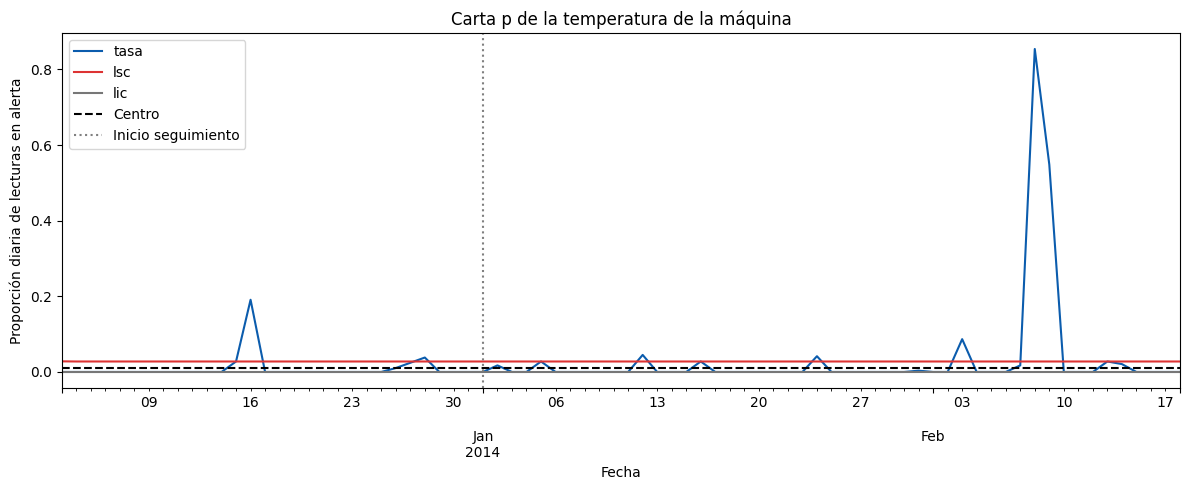

In [ ]:
ax = diario[["tasa", "lsc", "lic"]].plot(figsize=(12, 5), color=["#0B5CAD", "#D33", "#777"])
ax.axhline(pbar, color="black", ls="--", label="Centro")
ax.axvline(CORTE, color="gray", ls=":", label="Inicio seguimiento")
ax.set(ylabel="Proporción diaria de lecturas en alerta", xlabel="Fecha", title="Carta p de la temperatura de la máquina")
ax.legend(); plt.tight_layout(); plt.show()

## Paso 6. Convertir alertas en una cola de revisión
Un **episodio** agrupa las alertas separadas por 30 minutos o menos: es la unidad que el equipo revisa. La capacidad de **1 episodio por día** es un **supuesto académico**. La prioridad es la puntuación máxima del episodio. Se calcula la cola y se contrasta con las ventanas de NAB: un episodio coincide con una ventana si se superponen en el tiempo.

In [ ]:
CAPACIDAD_DIA = 1
alertas = feat.loc[feat.alerta, ["score"]].reset_index()
# Un episodio nuevo empieza cuando pasan más de 30 minutos desde la alerta anterior
alertas["episodio"] = (alertas.timestamp.diff() > pd.Timedelta(minutes=30)).cumsum()
episodios = alertas.groupby("episodio").agg(inicio=("timestamp", "min"), fin=("timestamp", "max"),
                                            lecturas=("score", "size"), score_max=("score", "max"))
episodios["dia"] = episodios.inicio.dt.normalize()
# Coincidencia con una ventana de referencia: superposición en el tiempo
episodios["en_ventana"] = [any((i <= b) and (f >= a) for a, b in ventanas) for i, f in zip(episodios.inicio, episodios.fin)]
ep = episodios[episodios.inicio >= CORTE].copy()
# Prioridad dentro de cada día por puntuación máxima; se revisan los primeros hasta completar la capacidad
ep["orden_dia"] = ep.groupby("dia").score_max.rank(method="first", ascending=False)
ep["revisable"] = ep.orden_dia <= CAPACIDAD_DIA
print("Episodios en el seguimiento:", len(ep), "· revisables:", int(ep.revisable.sum()), "· en cola:", int((~ep.revisable).sum()))
print("Episodios que coinciden con una ventana:", int(ep.en_ventana.sum()))
print("Lecturas en alerta dentro de ventanas:", int((feat.loc[~base, "alerta"] & en_ventana[~base]).sum()), "de", int(feat.loc[~base, "alerta"].sum()))
display(ep.sort_values("score_max", ascending=False).head(10).round(3))

Episodios en el seguimiento: 17 · revisables: 11 · en cola: 6
Episodios que coinciden con una ventana: 2
Lecturas en alerta dentro de ventanas: 404 de 495


,inicio,fin,lecturas,score_max,dia,en_ventana,orden_dia,revisable
episodio,,,,,,,,
18,2014-02-08 02:40:00,2014-02-09 13:05:00,403,0.793,2014-02-08,True,1.0,True
15,2014-02-03 11:50:00,2014-02-03 13:10:00,17,0.761,2014-02-03,False,1.0,True
12,2014-01-24 12:50:00,2014-01-24 13:45:00,12,0.679,2014-01-24,False,1.0,True
14,2014-02-03 00:10:00,2014-02-03 00:45:00,8,0.660,2014-02-03,False,2.0,False
9,2014-01-12 09:35:00,2014-01-12 10:10:00,8,0.644,2014-01-12,False,1.0,True
19,2014-02-13 19:30:00,2014-02-13 19:45:00,4,0.640,2014-02-13,False,1.0,True
8,2014-01-12 08:25:00,2014-01-12 08:45:00,5,0.640,2014-01-12,False,2.0,False
11,2014-01-16 13:00:00,2014-01-16 13:25:00,6,0.637,2014-01-16,False,1.0,True
7,2014-01-05 17:50:00,2014-01-05 18:25:00,8,0.634,2014-01-05,False,1.0,True


## Paso 7. Sensibilidad del umbral
Compare los percentiles base 98, 99 y 99,5. Para cada uno reporte alertas de seguimiento, episodios, episodios que coinciden con una ventana, días fuera de control y cola con la capacidad de 1 episodio por día. El umbral se calcula siempre en la línea base.

In [ ]:
filas = []
for q in [0.98, 0.99, 0.995]:
    corte_q = feat.loc[base, "score"].quantile(q)
    a = feat.score >= corte_q
    pq = a[base].mean()
    n_dia = a.groupby(a.index.normalize()).size()
    k_dia = a.groupby(a.index.normalize()).sum()
    lsc_q = pq + 3 * np.sqrt(pq * (1 - pq) / n_dia)
    fuera_q = int(((k_dia / n_dia > lsc_q) & (n_dia.index >= CORTE)).sum())
    ix = a[a].index.to_series()
    nuevo = (ix.diff() > pd.Timedelta(minutes=30)).cumsum()
    e = pd.DataFrame({"inicio": ix.groupby(nuevo).min(), "fin": ix.groupby(nuevo).max()})
    e = e[e.inicio >= CORTE]
    e["en_ventana"] = [any((i <= b2) and (f >= a2) for a2, b2 in ventanas) for i, f in zip(e.inicio, e.fin)]
    cola = int((e.groupby(e.inicio.dt.normalize()).size() - CAPACIDAD_DIA).clip(lower=0).sum())
    filas.append({"percentil_base": q, "umbral": corte_q, "alertas": int(a[~base].sum()), "episodios": len(e),
                  "en_ventana": int(e.en_ventana.sum()), "dias_fuera": fuera_q, "cola": cola})
sensibilidad = pd.DataFrame(filas)
display(sensibilidad)

,percentil_base,umbral,alertas,episodios,en_ventana,dias_fuera,cola
0,0.980,0.559949,686,31,4,11,15
1,0.990,0.606017,495,17,2,8,6
2,0.995,0.692755,31,3,2,3,0


PREGUNTA 3.1
Lecturas en línea base ampliada: 12660
Lecturas en seguimiento: 9792
Nuevo umbral p99: 0.599724
Alertas en línea base: 127
Alertas en seguimiento: 501
Nueva proporción promedio: 0.01003
Días fuera de control: 6
['2014-01-16', '2014-01-24', '2014-02-03', '2014-02-08', '2014-02-09', '2014-02-13']


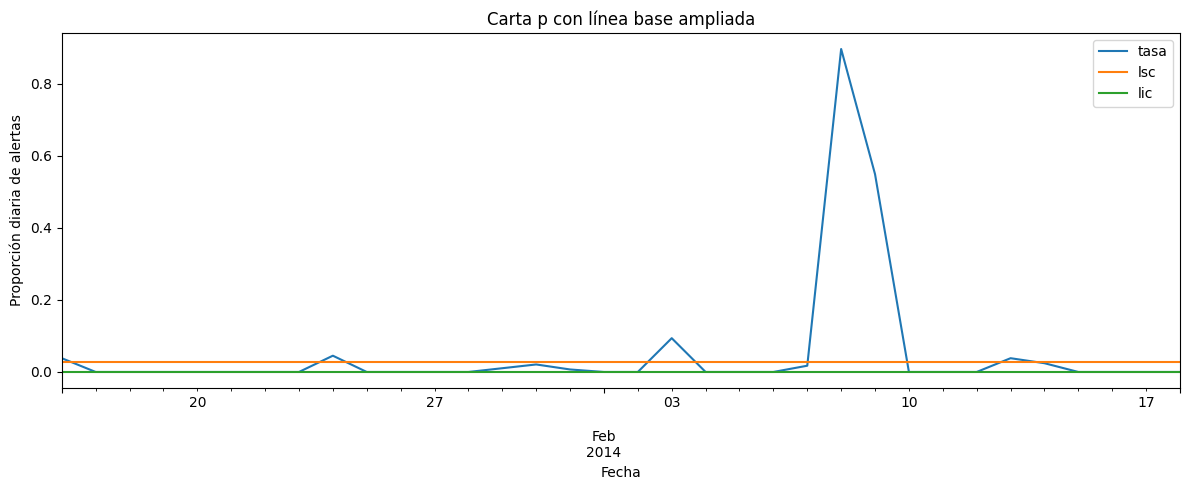

In [9]:
# PREGUNTA 3.1: LINEA BASE AMPLIADA

import pandas as pd
import numpy as np
from sklearn.ensemble import IsolationForest
import matplotlib.pyplot as plt

# 1. Definir la nueva línea base:
# del 3 de diciembre de 2013 al 15 de enero de 2014
CORTE_NUEVO = pd.Timestamp("2014-01-16")

base_nueva = feat.index < CORTE_NUEVO
seguimiento_nuevo = feat.index >= CORTE_NUEVO

# 2. Entrenar un modelo nuevo con la línea base ampliada
modelo_nuevo = IsolationForest(
    n_estimators=150,
    max_samples=5000,
    random_state=2026,
    n_jobs=-1
)

variables = ["valor", "media_1h", "desv_1h", "cambio_1h"]

modelo_nuevo.fit(feat.loc[base_nueva, variables])

# 3. Calcular puntuaciones con el nuevo modelo
score_base_nueva = -modelo_nuevo.score_samples(
    feat.loc[base_nueva, variables]
)

score_seguimiento_nuevo = -modelo_nuevo.score_samples(
    feat.loc[seguimiento_nuevo, variables]
)

# 4. Calcular el nuevo umbral p99 (Cambiado de .quantile a np.percentile para evitar AttributeError)
umbral_nuevo = np.percentile(score_base_nueva, 99)

# 5. Identificar las alertas
alertas_base_nueva = score_base_nueva > umbral_nuevo
alertas_seguimiento_nuevo = score_seguimiento_nuevo > umbral_nuevo

print("PREGUNTA 3.1")
print("Lecturas en línea base ampliada:", len(score_base_nueva))
print("Lecturas en seguimiento:", len(score_seguimiento_nuevo))
print("Nuevo umbral p99:", round(umbral_nuevo, 6))
print("Alertas en línea base:", int(alertas_base_nueva.sum()))
print("Alertas en seguimiento:", int(alertas_seguimiento_nuevo.sum()))

# 6. Recalcular la carta p usando el nuevo modelo
alertas_nuevas = pd.Series(
    False, index=feat.index
)

alertas_nuevas.loc[base_nueva] = alertas_base_nueva
alertas_nuevas.loc[seguimiento_nuevo] = alertas_seguimiento_nuevo

diario_nuevo = pd.DataFrame({
    "alerta": alertas_nuevas,
    "seguimiento": seguimiento_nuevo
})

diario_nuevo = diario_nuevo.groupby(
    diario_nuevo.index.normalize()
).agg(
    lecturas=("alerta", "size"),
    alertas=("alerta", "sum"),
    seguimiento=("seguimiento", "max")
)

pbar_nuevo = (
    alertas_base_nueva.sum() / len(alertas_base_nueva)
)

diario_nuevo["tasa"] = (
    diario_nuevo["alertas"] / diario_nuevo["lecturas"]
)

diario_nuevo["lsc"] = (
    pbar_nuevo
    + 3 * np.sqrt(
        pbar_nuevo * (1 - pbar_nuevo)
        / diario_nuevo["lecturas"]
    )
)

diario_nuevo["lic"] = np.maximum(
    0,
    pbar_nuevo
    - 3 * np.sqrt(
        pbar_nuevo * (1 - pbar_nuevo)
        / diario_nuevo["lecturas"]
    )
)

diario_nuevo["fuera"] = (
    (diario_nuevo["tasa"] > diario_nuevo["lsc"])
    | (diario_nuevo["tasa"] < diario_nuevo["lic"])
)

dias_fuera_nuevos = diario_nuevo[
    diario_nuevo["seguimiento"] & diario_nuevo["fuera"]
]

print("Nueva proporción promedio:", round(pbar_nuevo, 5))
print("Días fuera de control:", len(dias_fuera_nuevos))
print([
    str(d)[:10] for d in dias_fuera_nuevos.index
])

# 7. Mostrar la nueva carta p
ax = diario_nuevo.loc[
    diario_nuevo["seguimiento"],
    ["tasa", "lsc", "lic"]
].plot(figsize=(12, 5))

ax.set(
    ylabel="Proporción diaria de alertas",
    xlabel="Fecha",
    title="Carta p con línea base ampliada"
)

plt.tight_layout()
plt.show()

## Tres retos individuales — diez ítems
Responda cada pregunta con sus propias palabras y con las cifras de su ejecución.

### Pregunta 1.1
Cuantifique las marcas repetidas, los huecos y el rango de la serie, y explique dos causas posibles de las lecturas muy bajas.

**Respuesta:**

La serie original contenía 22,695 registros, desde el 2 de diciembre de 2013 hasta el 19 de febrero de 2014. Durante la limpieza se identificaron 12 marcas de tiempo duplicadas, por lo que quedaron 22,683 lecturas útiles. No se encontraron lecturas fuera de la frecuencia esperada de cinco minutos y se trabajó con 22,464 lecturas correspondientes a días completos.

La temperatura presentó un promedio de 85.87, una desviación estándar de 13.80, un mínimo de 2.08 y un máximo de 108.51. Además, se encontraron 12 lecturas inferiores a 20, que se alejan considerablemente del comportamiento habitual.

Estas lecturas bajas podrían deberse a una caída real de temperatura por una parada o enfriamiento del sistema, o a un problema de medición, como una falla del sensor o una interrupción en la transmisión de datos. Por ello, es necesario investigar antes de considerarlas fallas reales del equipo.

### Pregunta 1.2
Describa dos episodios del top 10 con cifras (inicio, duración, lecturas en alerta y puntuación) y dos explicaciones operativas posibles para cada uno.

**Respuesta:**

Dos episodios que destacan en el análisis son:

- **Episodio 18:** comenzó el 8 de febrero de 2014 a las 02:40 y terminó el 9 de febrero a las 13:05. Tuvo una duración de 34 horas y 25 minutos, con 403 lecturas en alerta y una puntuación máxima de anomalía de 0.793. Podría estar relacionado con un cambio importante en las condiciones de operación o con una falla persistente del sensor.

- **Episodio 15:** comenzó el 3 de febrero de 2014 a las 11:50 y terminó a las 13:10. Tuvo una duración de 1 hora y 20 minutos, con 17 lecturas en alerta y una puntuación máxima de 0.761. Podría explicarse por una variación temporal de la carga de trabajo o por una perturbación en la medición.

Estas explicaciones son hipótesis que deben verificarse mediante los registros operativos y de mantenimiento antes de confirmar una causa.

### Pregunta 1.3
Identifique los días fuera de control e indique por qué son señales para investigar.

**Respuesta:**

En el periodo de seguimiento se identificaron ocho días fuera de los límites de control de la carta p: 5, 12, 16 y 24 de enero, y 3, 8, 9 y 13 de febrero de 2014.

Los casos más destacados fueron el 8 de febrero, con 246 alertas de 288 lecturas (85.42 %), y el 9 de febrero, con 158 de 288 lecturas (54.86 %).

Estos días representan señales que deben investigarse porque la proporción de lecturas anómalas supera el límite superior de control establecido en 0.027724. Sin embargo, estar fuera de control no significa necesariamente que exista una falla confirmada, sino que el comportamiento del proceso se alejó de lo esperado según la línea base.

### Pregunta 1.4
Proponga tres verificaciones externas antes de concluir una falla.

**Respuesta:**

Antes de concluir que existe una falla en el equipo, realizaría tres verificaciones:

1. Revisar el sensor, comprobando su calibración, conexión y estado físico para descartar errores de medición.
2. Consultar los registros operativos y de mantenimiento para identificar posibles cambios de carga, paradas o intervenciones durante las fechas de las anomalías.
3. Realizar una inspección física del equipo y comparar las lecturas con otro sensor independiente para confirmar si la variación realmente ocurrió.

Estas verificaciones permiten distinguir entre una falla real del proceso y un problema relacionado con la instrumentación o la recopilación de datos.

### Pregunta 2.1
Compare los tres umbrales con alertas, episodios, días fuera de control y cola.

**Respuesta:**

Se compararon tres umbrales de detección utilizando los percentiles 98, 99 y 99.5 de las puntuaciones de anomalía calculadas sobre la línea base.

| Percentil | Umbral | Alertas | Episodios | Días fuera de control | Cola |
|---|---:|---:|---:|---:|---:|
| 98 % | 0.559949 | 686 | 31 | 11 | 15 |
| 99 % | 0.606017 | 495 | 17 | 8 | 6 |
| 99.5 % | 0.692755 | 31 | 3 | 3 | 0 |

Los resultados muestran que, al aumentar el percentil, el umbral se vuelve más exigente y disminuye la cantidad de alertas y episodios detectados.

El percentil 98 identifica más anomalías, pero genera una carga elevada de trabajo y una cola de 15 episodios. El percentil 99 reduce esa carga, aunque todavía deja seis episodios pendientes. Finalmente, el percentil 99.5 genera 31 alertas agrupadas en tres episodios, con tres días fuera de control y sin cola pendiente.

Por lo tanto, la elección del umbral depende del equilibrio entre la capacidad de detección del modelo y los recursos disponibles para atender las alertas.

### Pregunta 2.2
Defienda un umbral bajo 1 revisión por día y declare el costo de oportunidad.

**Respuesta:**

Considerando que el equipo de mantenimiento tiene capacidad para revisar como máximo un episodio por día, recomendaría utilizar inicialmente el percentil 99.5.

Con este umbral se obtienen 31 alertas agrupadas en tres episodios, tres días fuera de control y ninguna cola pendiente de revisión. Esto permite mantener una carga de trabajo manejable y concentrarse en las anomalías más relevantes.

El costo de oportunidad es que se pueden dejar de detectar anomalías menos extremas. Por ejemplo, con el percentil 99 se identificaron 17 episodios, mientras que con el 99.5 solamente se detectaron tres. Por ello, aunque el percentil 99.5 facilita la gestión operativa, se debe revisar periódicamente que no se estén perdiendo señales importantes.

### Pregunta 2.3
Para cada ventana de referencia del seguimiento, calcule cuántas horas antes o después de su inicio apareció el primer episodio y explique por qué esa diferencia no demuestra capacidad de predicción.

**Respuesta:**

In [6]:
import pandas as pd
import numpy as np
from sklearn.ensemble import IsolationForest

# 1. Recuperar y preparar los datos
raw = pd.read_csv(
    "https://raw.githubusercontent.com/numenta/NAB/master/data/realKnownCause/machine_temperature_system_failure.csv",
    parse_dates=["timestamp"]
)

raw = raw.drop_duplicates(
    subset="timestamp",
    keep="first"
)

df = raw.sort_values("timestamp").set_index("timestamp")
df = df.loc["2013-12-03":"2014-02-18 23:59"].copy()

# 2. Construir las cuatro variables
feat = pd.DataFrame({
    "valor": df["value"],
    "media_1h": df["value"].rolling(12).mean(),
    "desv_1h": df["value"].rolling(12).std(),
    "cambio_1h": df["value"].diff(12)
}).dropna()

variables = [
    "valor",
    "media_1h",
    "desv_1h",
    "cambio_1h"
]

# 3. Separar línea base y seguimiento
CORTE = pd.Timestamp("2014-01-01")

base = feat.index < CORTE

# 4. Entrenar Isolation Forest
modelo = IsolationForest(
    n_estimators=150,
    max_samples=5000,
    random_state=2026,
    n_jobs=-1
)

modelo.fit(feat.loc[base, variables])

# 5. Calcular puntuaciones y umbral
feat["score"] = -modelo.score_samples(feat[variables])

umbral = feat.loc[base, "score"].quantile(0.99)

# Mantener el criterio del laboratorio
feat["alerta"] = feat["score"] > umbral

print("Umbral:", round(umbral, 6))
print("Alertas en línea base:", feat.loc[base, "alerta"].sum())
print(
    "Alertas en seguimiento:",
    feat.loc[~base, "alerta"].sum()
)

# 6. Definir ventanas NAB del seguimiento
ventanas_seguimiento = [
    (
        "Ventana 3",
        pd.Timestamp("2014-01-27 14:20"),
        pd.Timestamp("2014-01-29 13:30")
    ),
    (
        "Ventana 4",
        pd.Timestamp("2014-02-07 14:55"),
        pd.Timestamp("2014-02-09 14:05")
    )
]

# 7. Reconstruir episodios
seguimiento_alertas = feat.loc[
    feat.index >= CORTE
].copy()

alertas_temp = seguimiento_alertas.loc[
    seguimiento_alertas["alerta"],
    ["score"]
].reset_index()

alertas_temp["episodio"] = (
    alertas_temp["timestamp"].diff() >
    pd.Timedelta(minutes=30)
).cumsum()

episodios = alertas_temp.groupby("episodio").agg(
    inicio=("timestamp", "min"),
    fin=("timestamp", "max"),
    lecturas=("timestamp", "count"),
    score_max=("score", "max")
).reset_index()

print("Episodios encontrados:", len(episodios))

# 8. Calcular diferencias horarias
resultados = []

for nombre, inicio_v, fin_v in ventanas_seguimiento:

    coincidentes = episodios[
        (episodios["inicio"] <= fin_v) &
        (episodios["fin"] >= inicio_v)
    ].sort_values("inicio")

    if not coincidentes.empty:
        primer_ep = coincidentes.iloc[0]
        tipo = "Coincide con ventana"

    else:
        posteriores = episodios[
            episodios["inicio"] > fin_v
        ].sort_values("inicio")

        if not posteriores.empty:
            primer_ep = posteriores.iloc[0]
            tipo = "Posterior a ventana"
        else:
            primer_ep = None
            tipo = "Sin episodios"

    if primer_ep is not None:

        diferencia = (
            primer_ep["inicio"] - inicio_v
        ).total_seconds() / 3600

        resultados.append({
            "Ventana": nombre,
            "Inicio ventana": inicio_v,
            "Inicio episodio": primer_ep["inicio"],
            "Diferencia (horas)": round(diferencia, 2),
            "Relación": (
                "Después de inicio"
                if diferencia >= 0
                else "Antes de inicio"
            ),
            "Tipo": tipo
        })

tabla_comparativa = pd.DataFrame(resultados)

display(tabla_comparativa)

Umbral: 0.606017
Alertas en línea base: 84
Alertas en seguimiento: 495
Episodios encontrados: 17


,Ventana,Inicio ventana,Inicio episodio,Diferencia (horas),Relación,Tipo
0,Ventana 3,2014-01-27 14:20:00,2014-01-31 10:20:00,92.00,Después de inicio,Posterior a ventana
1,Ventana 4,2014-02-07 14:55:00,2014-02-08 02:00:00,11.08,Después de inicio,Coincide con ventana


**Respuesta:**

Para la ventana 3, que comenzó el 27 de enero de 2014 a las 14:20, el primer episodio posterior apareció el 31 de enero a las 10:20, es decir, 92 horas después. No se encontró un episodio que coincidiera con esta ventana.

Para la ventana 4, que comenzó el 7 de febrero a las 14:55, el primer episodio apareció el 8 de febrero a las 02:00, aproximadamente 11.08 horas después del inicio de la ventana. En este caso, el episodio sí coincidió con el periodo de referencia.

Estas diferencias no demuestran que el modelo pueda predecir fallas, porque las ventanas NAB representan periodos de anomalías conocidas y no necesariamente el momento exacto en que comenzó un problema. El modelo permite identificar comportamientos anómalos, pero esto no significa que pueda anticipar su ocurrencia.

### Pregunta 3.1

Al ampliar la línea base del 3 de diciembre de 2013 al 15 de enero de 2014, se reentrenó el modelo Isolation Forest y se calculó nuevamente el umbral del percentil 99. La nueva línea base quedó conformada por 12,660 lecturas y el periodo de seguimiento por 9,792 lecturas.

El nuevo umbral fue **0.599724**, ligeramente inferior al original de 0.606017. Se identificaron 127 alertas en la línea base y 501 en el seguimiento, frente a las 84 y 495 alertas, respectivamente, del análisis original.

En la nueva carta p, la proporción promedio fue de 0.01003 y se identificaron **6 días fuera de control**: 16 y 24 de enero, y 3, 8, 9 y 13 de febrero de 2014. En el análisis original se habían encontrado 8 días fuera de control.

Por lo tanto, al ampliar la línea base aumentó ligeramente la cantidad de alertas en el seguimiento, pero disminuyeron los días fuera de control de 8 a 6. Esto indica que el modelo modificó su referencia de comportamiento normal al incorporar más datos para el entrenamiento. Sin embargo, estos cambios reflejan diferencias estadísticas en la detección y no necesariamente una variación en la cantidad de fallas reales del equipo.

### Pregunta 3.2
Compare el modelo con las cuatro variables y un modelo que usa solo la lectura (valor): alertas, episodios y coincidencia con las ventanas.

**Respuesta:**



In [11]:

# PREGUNTA 3.2: COMPARACIÓN DE MODELOS

# 1. Definir la línea base original y el seguimiento
CORTE = pd.Timestamp("2014-01-01")

base = feat.index < CORTE
seguimiento = feat.index >= CORTE

# 2. Definir las variables de cada modelo
variables_4 = [
    "valor",
    "media_1h",
    "desv_1h",
    "cambio_1h"
]

variables_1 = ["valor"]

# 3. Función para entrenar y evaluar cada modelo
def evaluar_modelo(columnas, nombre):

    modelo = IsolationForest(
        n_estimators=150,
        max_samples=5000,
        random_state=2026,
        n_jobs=-1
    )

    # Entrenar únicamente con la línea base
    modelo.fit(feat.loc[base, columnas])

    # Calcular puntuaciones
    score_base = -modelo.score_samples(
        feat.loc[base, columnas]
    )

    score_seguimiento = -modelo.score_samples(
        feat.loc[seguimiento, columnas]
    )

    # Umbral del percentil 99 (Cambiado a np.percentile para evitar el AttributeError)
    umbral = np.percentile(score_base, 99)

    # Identificar alertas en seguimiento
    alertas = score_seguimiento > umbral

    # Obtener fechas de las alertas
    fechas_alerta = feat.index[seguimiento][alertas]

    # Agrupar alertas separadas por más de 30 minutos
    serie_fechas = pd.Series(fechas_alerta)

    grupos = (
        serie_fechas.diff() > pd.Timedelta(minutes=30)
    ).cumsum()

    episodios = pd.DataFrame({
        "inicio": serie_fechas.groupby(grupos).min(),
        "fin": serie_fechas.groupby(grupos).max()
    })

    # Ventanas de referencia NAB del seguimiento
    ventanas_seguimiento = [
        (
            pd.Timestamp("2014-01-27 14:20"),
            pd.Timestamp("2014-01-29 13:30")
        ),
        (
            pd.Timestamp("2014-02-07 14:55"),
            pd.Timestamp("2014-02-09 14:05")
        )
    ]

    # Contar episodios que se superponen con alguna ventana
    coincidencias = 0

    for _, ep in episodios.iterrows():

        coincide = any(
            (ep["inicio"] <= fin_v) and
            (ep["fin"] >= inicio_v)
            for inicio_v, fin_v in ventanas_seguimiento
        )

        if coincide:
            coincidencias += 1

    # Devolver resultados
    return {
        "Modelo": nombre,
        "Umbral p99": round(umbral, 6),
        "Alertas": int(alertas.sum()),
        "Episodios": len(episodios),
        "Coincidencias con ventanas NAB": columnas_coinciden if 'columnas_coinciden' in locals() else coincidencias
    }


# 4. Evaluar el modelo de cuatro variables
resultado_4 = evaluar_modelo(
    variables_4,
    "Cuatro variables"
)

# 5. Evaluar el modelo de una variable
resultado_1 = evaluar_modelo(
    variables_1,
    "Solo valor"
)

# 6. Mostrar la comparación
comparacion = pd.DataFrame([
    resultado_4,
    resultado_1
])

display(comparacion)


,Modelo,Umbral p99,Alertas,Episodios,Coincidencias con ventanas NAB
0,Cuatro variables,0.606017,495,17,2
1,Solo valor,0.589176,459,4,1


Se compararon dos modelos Isolation Forest utilizando la misma línea base (del 3 al 31 de diciembre de 2013), el mismo periodo de seguimiento (del 1 de enero al 18 de febrero de 2014) y el percentil 99 como umbral de detección. La diferencia fue que el primer modelo utilizó cuatro variables (`valor`, `media_1h`, `desv_1h` y `cambio_1h`), mientras que el segundo utilizó únicamente la lectura de temperatura (`valor`).

El modelo de cuatro variables obtuvo un umbral de 0.606017 y detectó **495 alertas**, agrupadas en **17 episodios**, de los cuales **2 coincidieron con las ventanas de referencia de NAB**.

Por otro lado, el modelo que utilizó solamente la variable `valor` obtuvo un umbral de 0.589176 y detectó **459 alertas**, agrupadas en **4 episodios**. En este caso, ninguno de los episodios coincidió con las ventanas de referencia.

Los resultados muestran que el modelo de cuatro variables identificó más comportamientos anómalos y tuvo más coincidencias con los periodos señalados por NAB. Esto puede explicarse porque considera no solo el nivel de temperatura, sino también su promedio, variabilidad y cambio durante la última hora.

Por lo tanto, elegiría el modelo de cuatro variables, ya que presentó una mayor capacidad para identificar episodios relacionados con las ventanas de referencia. Sin embargo, también genera una mayor carga de revisión, por lo que es necesario considerar la capacidad disponible del equipo de mantenimiento.

### Pregunta 3.3
Redacte una recomendación ejecutiva de ocho líneas con cifras, responsable, acción, límite y condición de revisión.

**Respuesta:**

1. Recomiendo implementar inicialmente el modelo Isolation Forest con cuatro variables y un umbral del percentil 99, que detectó 495 alertas agrupadas en 17 episodios, con 2 coincidencias con las ventanas NAB.
2. Este modelo mostró mejores resultados que el modelo basado únicamente en la temperatura, que detectó 459 alertas, 4 episodios y ninguna coincidencia con las ventanas NAB.
3. El equipo de mantenimiento será responsable de revisar las alertas y verificar las posibles anomalías del equipo.
4. La revisión debe priorizar los episodios con mayor puntuación de anomalía, comenzando por los que coinciden con las ventanas de referencia.
5. Se establece como límite operativo una revisión de 1 episodio por día, para evitar sobrecargar al equipo.
6. Se recomienda evaluar periódicamente la calibración del sensor, los registros de operación y el estado físico de la máquina antes de confirmar una falla.
7. El modelo y su umbral deberán revisarse si aparecen fallas no detectadas, aumenta la cola de episodios o cambian las condiciones de operación.
8. Finalmente, las alertas deben considerarse señales para investigar y no pruebas definitivas de fallas, ya que el modelo identifica comportamientos inusuales, pero no determina sus causas.